In [1]:
import ast
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import linear_kernel
from IPython.display import display

# Place final_dataset.csv in the same folder as this notebook.
df = pd.read_csv('final_dataset.csv')
required = ['title', 'topics', 'description', 'transcript']
assert all(c in df.columns for c in required), f'Missing columns: {set(required)-set(df.columns)}'
df = df.reset_index(drop=True)
print('TED Talks:', len(df))

TED Talks: 4004


In [2]:
title = df['title'].fillna('').astype(str)
topics = df['topics'].fillna('').astype(str)
description = df['description'].fillna('').astype(str)
transcript = df['transcript'].fillna('').astype(str)

texts = {
    'A: Title + Topics': title + ' ' + topics,
    'B: Weighted Full Text (Milestone 3)':
        (title + ' ') * 5 + (topics + ' ') * 5 +
        (description + ' ') * 3 + transcript
}

def vectorize(text):
    vectorizer = TfidfVectorizer(
        lowercase=True, stop_words='english', max_features=30000,
        ngram_range=(1, 2), min_df=2, max_df=0.95,
        sublinear_tf=True, dtype=np.float32
    )
    return vectorizer.fit_transform(text)

models = {name: vectorize(text) for name, text in texts.items()}
for name, X in models.items():
    print(name, X.shape)

A: Title + Topics (4004, 7496)
B: Weighted Full Text (Milestone 3) (4004, 30000)


In [3]:
def topic_set(value):
    if pd.isna(value):
        return set()
    if isinstance(value, str):
        try:
            parsed = ast.literal_eval(value)
            if isinstance(parsed, (list, tuple, set)):
                return {str(x).strip().lower() for x in parsed if str(x).strip()}
        except (ValueError, SyntaxError):
            pass
        return {x.strip().lower() for x in value.split(',') if x.strip()}
    return set()

topic_sets = [topic_set(v) for v in df['topics']]
# Build an inverted index: topic -> talk indices (faster than all-pairs scanning).
topic_to_talks = {}
for i, tags in enumerate(topic_sets):
    for tag in tags:
        topic_to_talks.setdefault(tag, set()).add(i)

relevant = {}
for i, tags in enumerate(topic_sets):
    ids = set()
    for tag in tags:
        ids.update(topic_to_talks[tag])
    ids.discard(i)
    if ids:
        relevant[i] = ids

# Fixed sample for a fast, reproducible evaluation; same queries for both models.
MAX_QUERIES = 200
rng = np.random.default_rng(42)
query_ids = sorted(rng.choice(list(relevant), size=min(MAX_QUERIES, len(relevant)), replace=False).tolist()) if relevant else []
print('Eligible queries:', len(relevant), '| Evaluated queries:', len(query_ids))
assert query_ids, 'No queries with relevant talks found. Check topics formatting.' 

Eligible queries: 45 | Evaluated queries: 45


In [4]:
K = 5

def top_k(X, i, k=K):
    scores = linear_kernel(X[i], X).ravel()
    scores[i] = -np.inf
    k = min(k, len(scores) - 1)
    if k <= 0:
        return []
    idx = np.argpartition(scores, -k)[-k:]
    return idx[np.argsort(-scores[idx], kind='stable')].tolist()

def metrics_at_k(predictions, truth, k=K):
    hits = np.array([int(j in truth) for j in predictions[:k]])
    precision = hits.sum() / k
    recall = hits.sum() / len(truth)
    discounts = 1 / np.log2(np.arange(2, len(hits) + 2))
    dcg = np.sum(hits * discounts)
    idcg = np.sum(discounts[:min(k, len(truth))])
    ndcg = dcg / idcg if idcg else 0
    running_hits = np.cumsum(hits)
    ap = sum(running_hits[j] / (j+1) for j in range(len(hits)) if hits[j]) / min(k, len(truth))
    return precision, recall, ndcg, ap

rows = []
for name, X in models.items():
    for i in query_ids:
        predicted = top_k(X, i)
        p, r, ndcg, ap = metrics_at_k(predicted, relevant[i])
        rows.append([name, i, p, r, ndcg, ap])

results = pd.DataFrame(rows, columns=['Model','Query','Precision@5','Recall@5','NDCG@5','MAP@5'])
summary = results.groupby('Model', as_index=False)[['Precision@5','Recall@5','NDCG@5','MAP@5']].mean()
print('MODEL EVALUATION COMPARISON')
display(summary.round(4))

MODEL EVALUATION COMPARISON


,Model,Precision@5,Recall@5,NDCG@5,MAP@5
0,A: Title + Topics,0.3556,0.8405,0.8679,0.8219
1,B: Weighted Full Text (Milestone 3),0.2444,0.6627,0.6061,0.5364


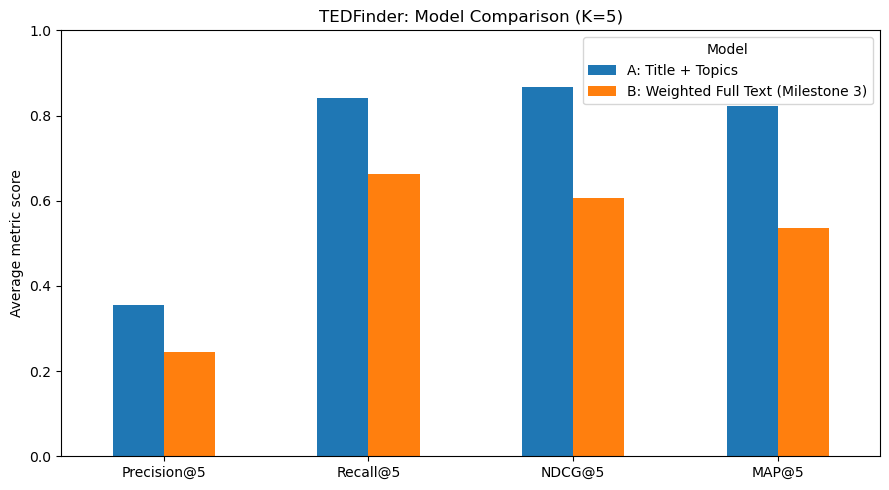

In [5]:
ax = summary.set_index('Model')[['Precision@5','Recall@5','NDCG@5','MAP@5']].T.plot(kind='bar', figsize=(9, 5), rot=0)
ax.set_title('TEDFinder: Model Comparison (K=5)')
ax.set_ylabel('Average metric score')
ax.set_ylim(0, 1)
plt.tight_layout()
plt.show()

In [6]:
best = summary.loc[summary['NDCG@5'].idxmax(), 'Model']
print('Best on topic-overlap proxy NDCG@5:', best)
print('Evaluation uses the same', len(query_ids), 'queries for both models.')
print('Limitation: Topic-based proxy relevance can favor the Title + Topics baseline.')
print('Final deployment choice should also consider manual relevance judgments.')
summary.to_csv('tedfinder_simple_evaluation.csv', index=False)
print('Saved: tedfinder_simple_evaluation.csv')

Best on topic-overlap proxy NDCG@5: A: Title + Topics
Evaluation uses the same 45 queries for both models.
Limitation: Topic-based proxy relevance can favor the Title + Topics baseline.
Final deployment choice should also consider manual relevance judgments.
Saved: tedfinder_simple_evaluation.csv
